# Part 3: Visualizations and Interpretation

**CS 22B, Fall 2026 · Team 12** · Section lead: Carolyna Sias

This notebook loads the cleaned file from Part 1 and the summary tables from Part 2, and makes one plot for each research question.

**Data source:** `data/neurons_clean.csv` (Part 1) and `data/layer_summary.csv`, `data/q4_summary.csv` (Part 2), from the Allen Cell Types Database, https://celltypes.brain-map.org

One row = one neuron recorded in a slice of mouse or human brain tissue.

## Set up and load

The next cell loads the cleaned data and the Part 2 tables. Run Parts 1 and 2 first so these files exist.

In [22]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

neurons = pd.read_csv("data/neurons_clean.csv")
layer_summary = pd.read_csv("data/layer_summary.csv")
q4_summary = pd.read_csv("data/q4_summary.csv")
print("Rows, columns:", neurons.shape)

Rows, columns: (2333, 12)


## Filter for fair comparisons

Like Part 2, the next cell keeps only spiny and aspiny cells, because there are too few sparsely spiny cells to compare.

In [23]:
neurons_2groups = neurons[neurons["dendrite_type"].isin(["spiny", "aspiny"])]
print("Rows kept:", len(neurons_2groups))

Rows kept: 2213


## Q1: Human vs. mouse neurons

The next cell draws a boxplot of input resistance, resting potential and rheobase for each species. The line in each box is the median.

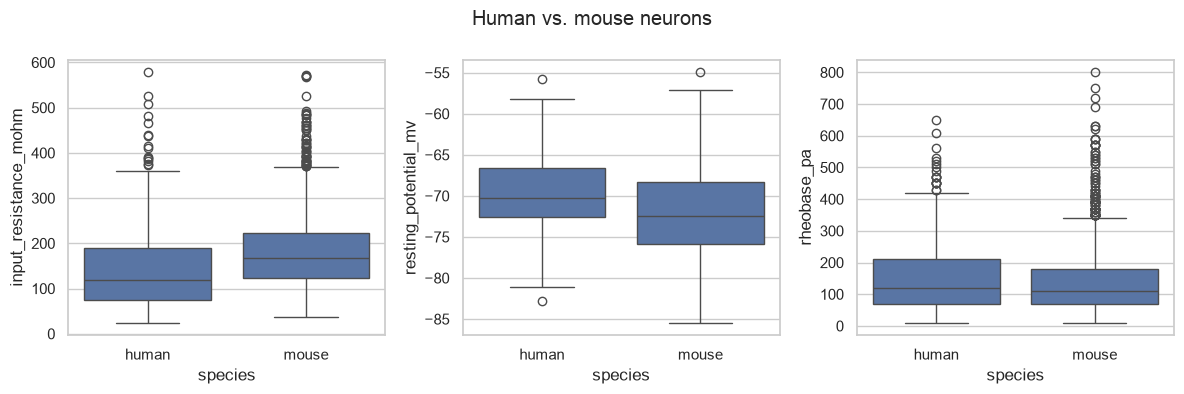

In [24]:
props = ["input_resistance_mohm", "resting_potential_mv", "rheobase_pa"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, prop in zip(axes, props):
    sns.boxplot(data=neurons, x="species", y=prop, ax=ax)
fig.suptitle("Human vs. mouse neurons")
plt.tight_layout()
plt.show()

## Q2: Spiny vs. aspiny neurons

The next cell compares spike shape and firing rate for spiny and aspiny cells in each species. Firing rate uses a log scale because a few cells fire much faster than the rest.

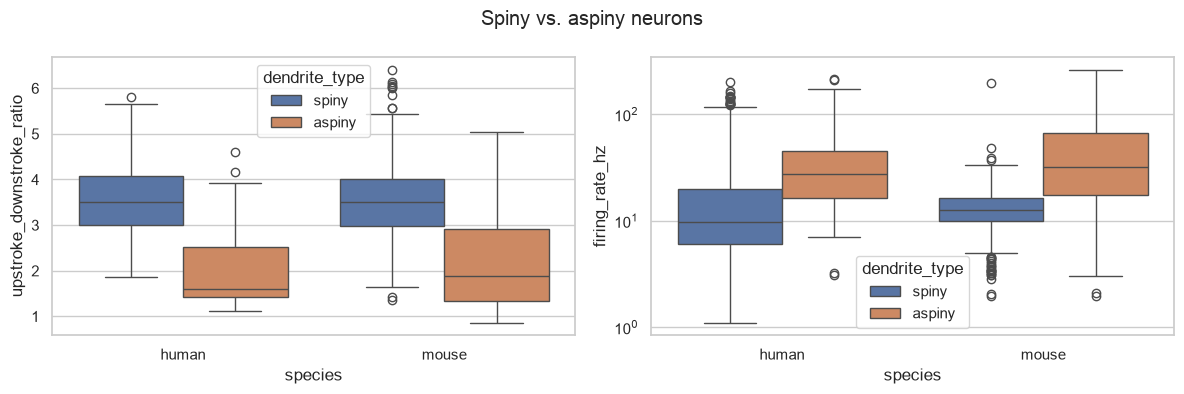

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=neurons_2groups, x="species", y="upstroke_downstroke_ratio", hue="dendrite_type", ax=axes[0])
sns.boxplot(data=neurons_2groups, x="species", y="firing_rate_hz", hue="dendrite_type", log_scale=True, ax=axes[1])
fig.suptitle("Spiny vs. aspiny neurons")
plt.tight_layout()
plt.show()

## Q3: Differences across cortical layers

The next cell plots the median of each property by layer for each species, using `layer_summary` from Part 2. Layers go from the brain surface (1) to the deepest layer (6).

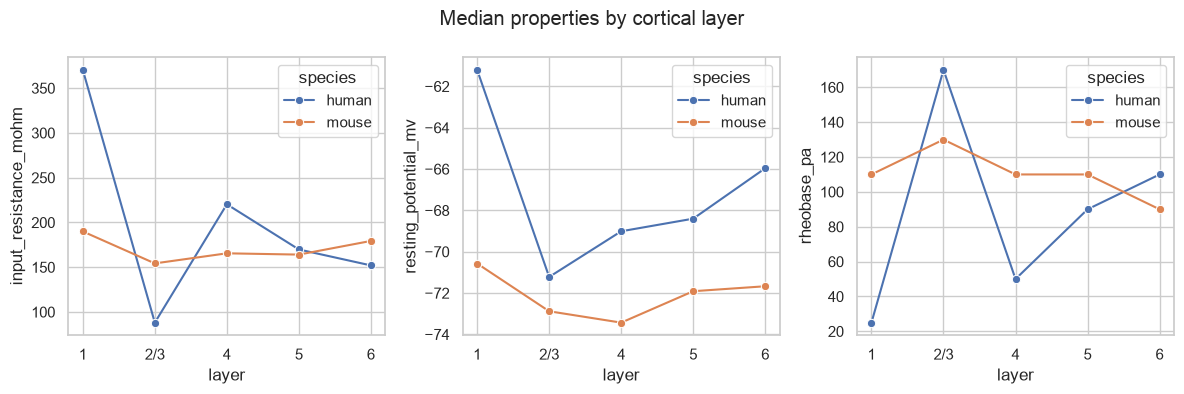

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, prop in zip(axes, props):
    sns.lineplot(data=layer_summary, x="layer", y=prop, hue="species", marker="o", ax=ax)
fig.suptitle("Median properties by cortical layer")
plt.tight_layout()
plt.show()

## Q4: Input resistance and firing rate

The next cell plots input resistance against firing rate for each species, colored by dendrite type. Both axes use a log scale. The table after it shows the correlations from Part 2.

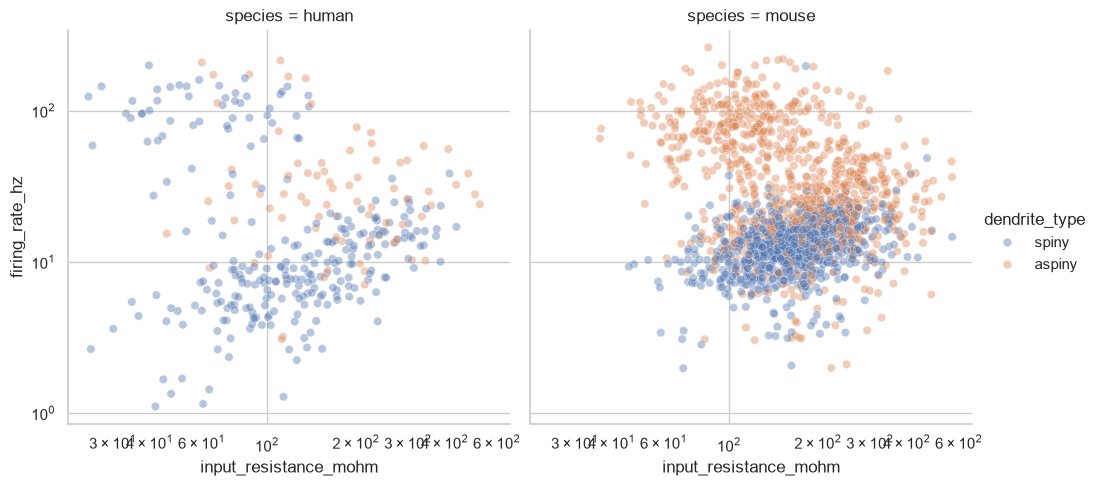

In [27]:
g = sns.relplot(data=neurons_2groups, x="input_resistance_mohm", y="firing_rate_hz",
                hue="dendrite_type", col="species", alpha=0.4)
g.set(xscale="log", yscale="log")
plt.show()

In [28]:
q4_summary.round(3)

,species,dendrite_type,correlation,n_cells
0,human,aspiny,-0.244,76
1,human,spiny,-0.280,268
2,mouse,aspiny,-0.326,862
3,mouse,spiny,0.222,854
